<a href="https://colab.research.google.com/github/onishchenkoanastasia5-glitch/Machine_learning/blob/main/%D0%9B%D0%A03_%D0%9E%D0%BD%D0%B8%D1%89%D0%B5%D0%BD%D0%BA%D0%BE_3_12_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**Студент(ка):Онищенко Анастасія
**Група:ФІТ 3-12

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
sns.set_style("whitegrid")

print("Бібліотеки імпортовано")

Бібліотеки імпортовано


## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:
# Спосіб для Google Colab: відкриється вікно вибору файлу.
# Закоментовано, щоб ноутбук можна було запустити повністю (Run all).

# from google.colab import files
# import io
# uploaded = files.upload()
# file_name = list(uploaded.keys())[0]
# df = pd.read_csv(io.BytesIO(uploaded[file_name]))
# print("Завантажено файл:", file_name)

### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download("prokshitha/home-value-insights")

# шукаємо всі csv-файли в папці датасету
csv_files = glob.glob(os.path.join(dataset_path, "*.csv"))
print("Знайдені файли:", csv_files)

df = pd.read_csv(csv_files[0])
print("Розмір датасету:", df.shape)

100%|██████████| 26.4k/26.4k [00:00<00:00, 33.4MB/s]

Extracting files...
Знайдені файли: ['/root/.cache/kagglehub/datasets/prokshitha/home-value-insights/versions/1/house_price_regression_dataset.csv']
Розмір датасету: (1000, 8)


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [4]:
print("Перші 10 рядків:")
display(df.head(10))

print("Кількість рядків і стовпців:", df.shape)
print()
print("Типи даних:")
print(df.dtypes)
print()
df.info()

Перші 10 рядків:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.5996,0,5,262382.8523
1,4272,3,3,2016,4.7530,1,6,985260.8545
2,3592,1,2,2016,3.6348,0,9,777977.3901
3,966,1,2,1977,2.7307,1,8,229698.9187
4,4926,2,1,1993,4.6991,0,8,1041740.8589
5,3944,5,3,1990,2.4759,2,8,879796.9835
6,3671,1,2,2012,4.9120,0,1,814427.8614
7,3419,1,1,1972,2.8053,1,1,703413.1109
8,630,3,3,1997,1.0143,1,8,173875.0372
9,2185,4,2,1981,3.9416,2,5,504176.5061


Кількість рядків і стовпців: (1000, 8)

Типи даних:
Square_Footage            int64
Num_Bedrooms              int64
Num_Bathrooms             int64
Year_Built                int64
Lot_Size                float64
Garage_Size               int64
Neighborhood_Quality      int64
House_Price             float64
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [5]:
duplicates = df[df.duplicated()]
print("Кількість дубльованих рядків:", len(duplicates))

if len(duplicates) == 0:
    print("Дублікатів немає, нічого видаляти не потрібно")

Кількість дубльованих рядків: 0
Дублікатів немає, нічого видаляти не потрібно


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [6]:
missing = pd.DataFrame({
    "Кількість пропусків": df.isnull().sum(),
    "Відсоток пропусків": df.isnull().mean() * 100
})
missing

,Кількість пропусків,Відсоток пропусків
Square_Footage,0,0.0000
Num_Bedrooms,0,0.0000
Num_Bathrooms,0,0.0000
Year_Built,0,0.0000
Lot_Size,0,0.0000
Garage_Size,0,0.0000
Neighborhood_Quality,0,0.0000
House_Price,0,0.0000


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Square_Footage,1000.0000,2815.4220,1255.5149,503.0000,1749.5000,2862.5000,3849.5000,4999.0000
Num_Bedrooms,1000.0000,2.9900,1.4276,1.0000,2.0000,3.0000,4.0000,5.0000
Num_Bathrooms,1000.0000,1.9730,0.8203,1.0000,1.0000,2.0000,3.0000,3.0000
Year_Built,1000.0000,1986.5500,20.6329,1950.0000,1969.0000,1986.0000,2004.2500,2022.0000
Lot_Size,1000.0000,2.7781,1.2979,0.5061,1.6659,2.8097,3.9233,4.9893
Garage_Size,1000.0000,1.0220,0.8150,0.0000,0.0000,1.0000,2.0000,2.0000
Neighborhood_Quality,1000.0000,5.6150,2.8871,1.0000,3.0000,6.0000,8.0000,10.0000
House_Price,1000.0000,618861.0186,253568.0584,111626.8534,401648.2289,628267.2911,827141.2776,1108236.8363


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [8]:
nq_counts = df["Neighborhood_Quality"].value_counts()
print("Частоти (від найчастішого до найрідшого):")
print(nq_counts)
print()
print("Кількість унікальних значень:", df["Neighborhood_Quality"].nunique())

Частоти (від найчастішого до найрідшого):
Neighborhood_Quality
10    123
5     109
2     105
7     102
6     101
4      99
8      97
1      91
9      88
3      85
Name: count, dtype: int64

Кількість унікальних значень: 10


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

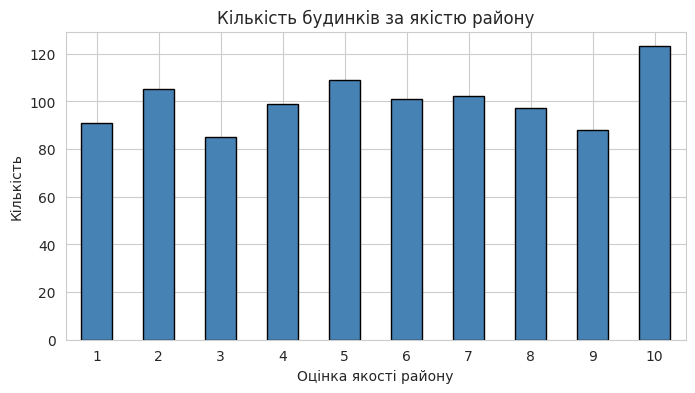

In [9]:
nq_counts.sort_index().plot(kind="bar", figsize=(8, 4), color="steelblue", edgecolor="black")
plt.title("Кількість будинків за якістю району")
plt.xlabel("Оцінка якості району")
plt.ylabel("Кількість")
plt.xticks(rotation=0)
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [10]:
bath_counts = df["Num_Bathrooms"].value_counts().sort_index()
print(bath_counts)
print()
print("У відсотках:")
print((df["Num_Bathrooms"].value_counts(normalize=True).sort_index() * 100).round(1))

Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64

У відсотках:
Num_Bathrooms
1   35.0000
2   32.7000
3   32.3000
Name: proportion, dtype: float64


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

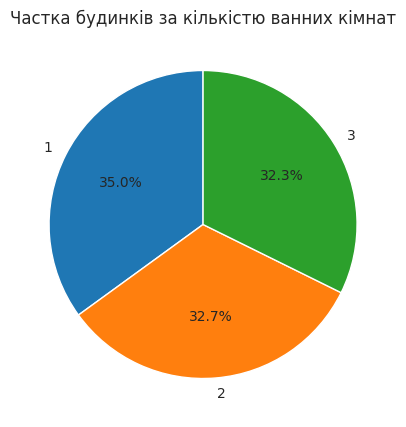

In [11]:
plt.figure(figsize=(5, 5))
plt.pie(bath_counts, labels=bath_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Частка будинків за кількістю ванних кімнат")
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

**Аналіз:** гістограми показують, що більшість ознак розподілені приблизно рівномірно. На попарних графіках чітко видно лінійну залежність ціни від площі будинку. Для `Lot_Size`, `Garage_Size` та `Neighborhood_Quality` явної залежності з ціною немає.

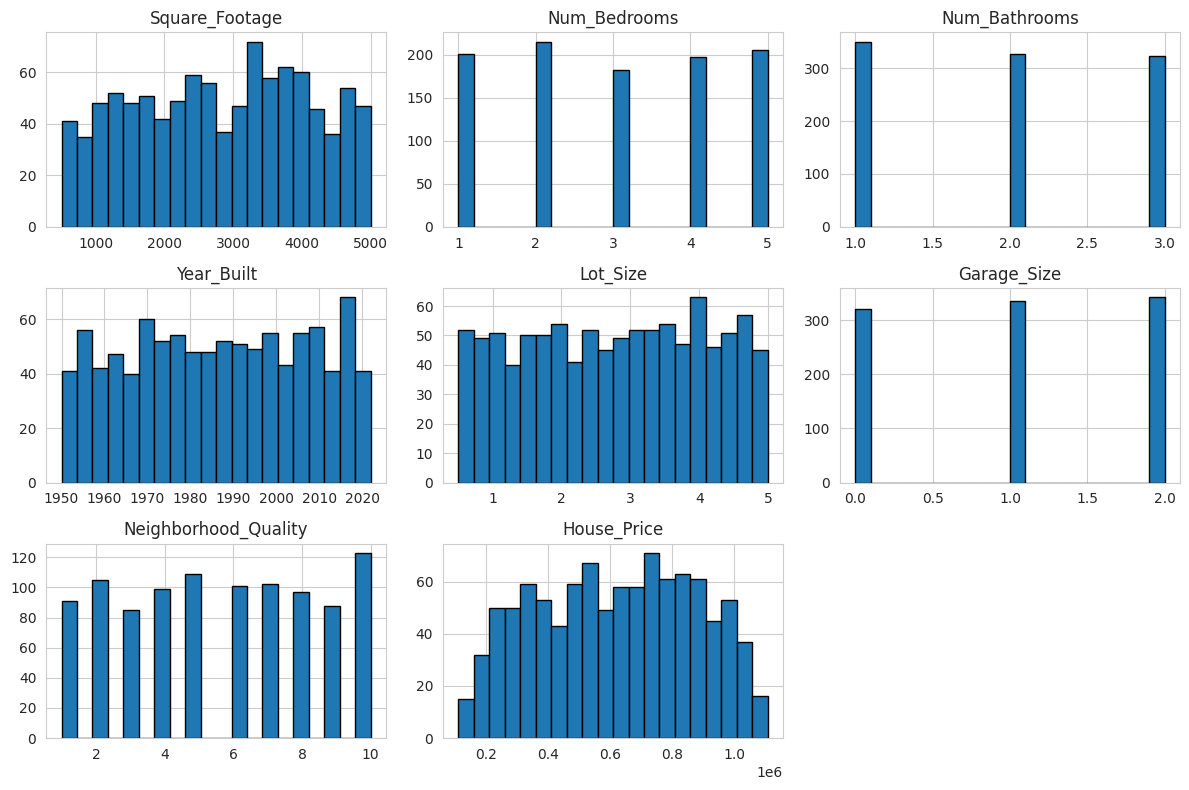

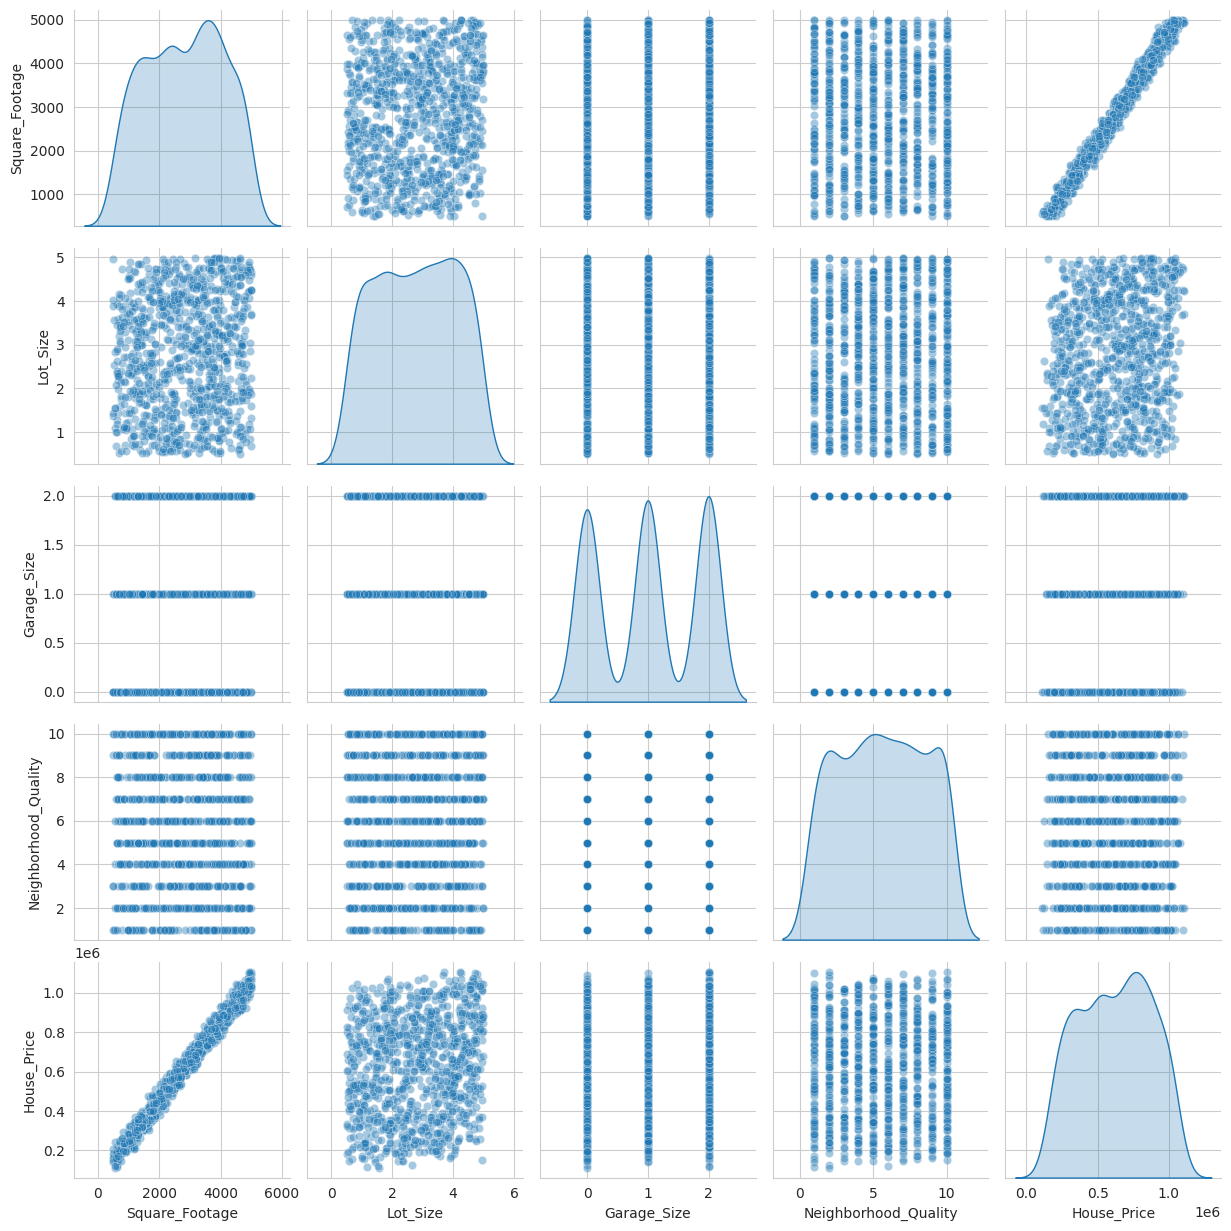

In [12]:
# додатково: гістограми всіх ознак
df.hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

# попарні графіки
sns.pairplot(df[["Square_Footage", "Lot_Size", "Garage_Size", "Neighborhood_Quality", "House_Price"]],
             diag_kind="kde", plot_kws={"alpha": 0.4})
plt.show()

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

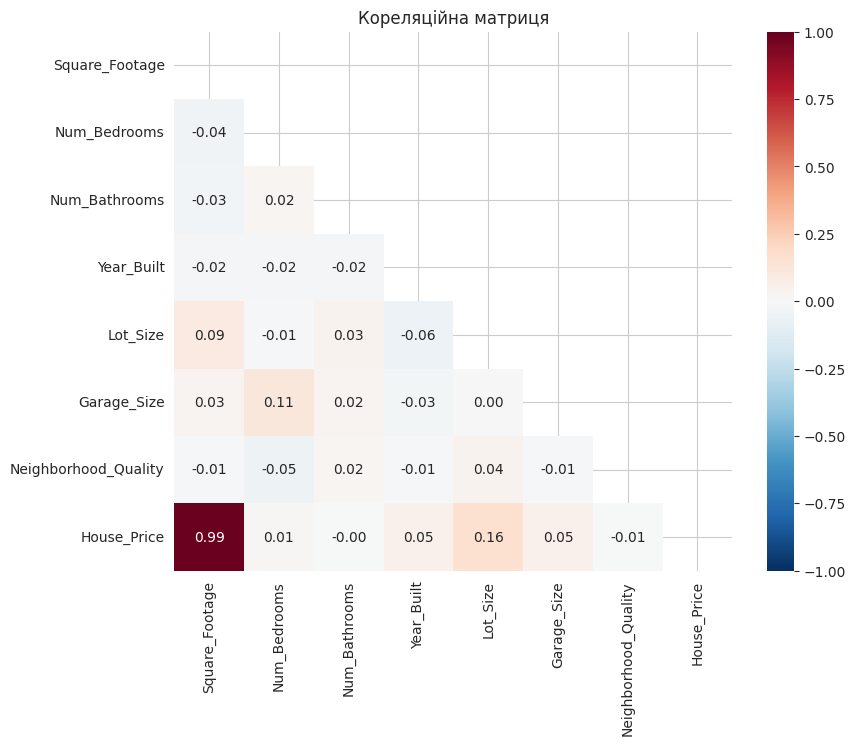

In [13]:
corr_matrix = df.corr(numeric_only=True)

# маска, щоб показати тільки нижній трикутник матриці
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Кореляційна матриця")
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

Square_Footage          0.9913
Lot_Size                0.1604
Garage_Size             0.0521
Year_Built              0.0520
Num_Bedrooms            0.0146
Num_Bathrooms          -0.0019
Neighborhood_Quality   -0.0078
Name: House_Price, dtype: float64


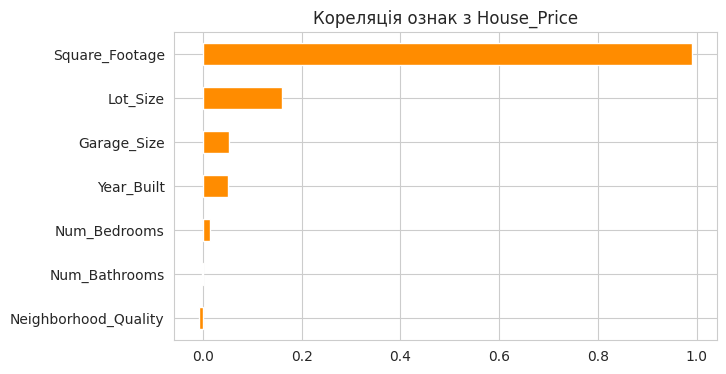

In [14]:
target_corr = corr_matrix["House_Price"].drop("House_Price").sort_values(ascending=False)
print(target_corr)

target_corr.plot(kind="barh", figsize=(7, 4), color="darkorange")
plt.title("Кореляція ознак з House_Price")
plt.gca().invert_yaxis()
plt.show()

## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [15]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Інструменти sklearn імпортовано")

Інструменти sklearn імпортовано


### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [16]:
target = "House_Price"
features = [col for col in df.columns if col != target]

X = df[features]
y = df[target]

print("Ознаки:", features)
print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

Ознаки: ['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality']
Розмір X: (1000, 7)
Розмір y: (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Навчальна вибірка:", len(X_train), "рядків")
print("Тестова вибірка:", len(X_test), "рядків")
print("Частка тестової вибірки:", round(len(X_test) / len(X), 2))

Навчальна вибірка: 800 рядків
Тестова вибірка: 200 рядків
Частка тестової вибірки: 0.2


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [18]:
lin_reg = make_pipeline(StandardScaler(), LinearRegression())
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
lasso = make_pipeline(StandardScaler(), Lasso(alpha=1.0, max_iter=10000))
rf = RandomForestRegressor(n_estimators=100, random_state=0)
gb = GradientBoostingRegressor(random_state=0)

models = {
    "Linear Regression": lin_reg,
    "Ridge": ridge,
    "Lasso": lasso,
    "Random Forest": rf,
    "Gradient Boosting": gb
}

for name, model in models.items():
    print(name, "->", model)

Linear Regression -> Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearregression', LinearRegression())])
Ridge -> Pipeline(steps=[('standardscaler', StandardScaler()), ('ridge', Ridge())])
Lasso -> Pipeline(steps=[('standardscaler', StandardScaler()),
                ('lasso', Lasso(max_iter=10000))])
Random Forest -> RandomForestRegressor(random_state=0)
Gradient Boosting -> GradientBoostingRegressor(random_state=0)


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

Linear Regression - навчено
Ridge - навчено
Lasso - навчено
Random Forest - навчено
Gradient Boosting - навчено


,R2,MAE,MSE,RMSE
Linear Regression,0.9984,8174.5836,101434798.5056,10071.4844
Lasso,0.9984,8174.7484,101436558.1801,10071.5718
Ridge,0.9984,8241.5869,102480990.0087,10123.2895
Gradient Boosting,0.9965,12304.3872,225017632.0263,15000.5877
Random Forest,0.9940,16042.8021,385898191.9941,19644.2916


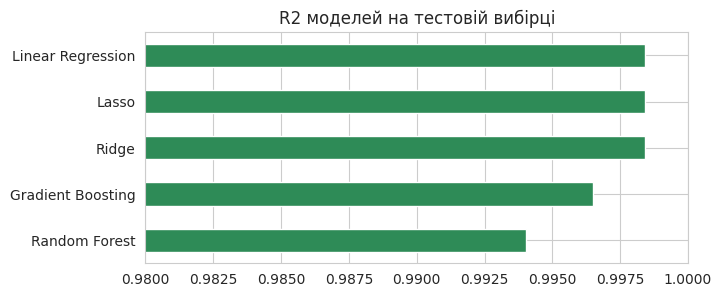

In [19]:
metrics = {"R2": [], "MAE": [], "MSE": []}
preds = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    preds[name] = pred

    metrics["R2"].append(r2_score(y_test, pred))
    metrics["MAE"].append(mean_absolute_error(y_test, pred))
    metrics["MSE"].append(mean_squared_error(y_test, pred))
    print(name, "- навчено")

results = pd.DataFrame(metrics, index=models.keys())
results["RMSE"] = np.sqrt(results["MSE"])  # додатково
display(results.sort_values("R2", ascending=False))

# додатково: порівняння R2 на діаграмі
results["R2"].sort_values().plot(kind="barh", figsize=(7, 3), color="seagreen")
plt.title("R2 моделей на тестовій вибірці")
plt.xlim(0.98, 1.0)
plt.show()

### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

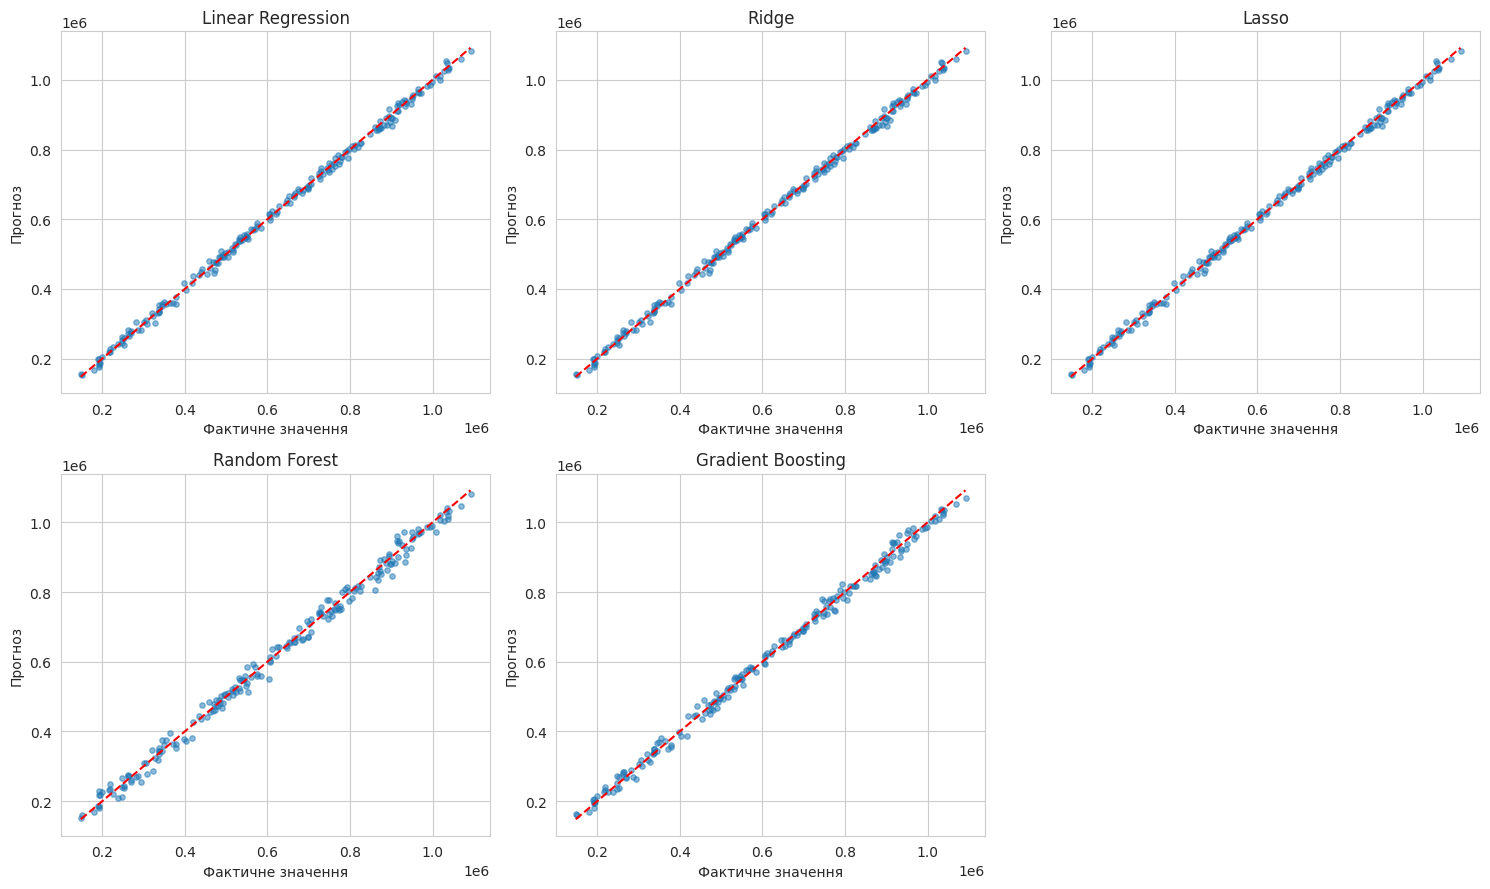

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

min_val, max_val = y_test.min(), y_test.max()

for i, (name, pred) in enumerate(preds.items()):
    axes[i].scatter(y_test, pred, alpha=0.5, s=15)
    axes[i].plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--")
    axes[i].set_title(name)
    axes[i].set_xlabel("Фактичне значення")
    axes[i].set_ylabel("Прогноз")

axes[5].axis("off")  # шостий графік порожній
plt.tight_layout()
plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [21]:
param_grid = {
    "n_estimators": [50, 100, 150],
    "max_features": ["sqrt", "log2", None],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 4]
}

rf_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=0),
    param_grid=param_grid,
    scoring="r2",
    cv=3,
    n_jobs=-1,
    verbose=1
)
rf_search.fit(X_train, y_train)

print("Найкращі параметри:")
for key, value in rf_search.best_params_.items():
    print(" ", key, "=", value)
print("Найкращий середній R2 (крос-валідація):", round(rf_search.best_score_, 4))

# додатково: топ-5 комбінацій
cv_res = pd.DataFrame(rf_search.cv_results_)
cv_res[["params", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(5)

Fitting 3 folds for each of 54 candidates, totalling 162 fits
Найкращі параметри:
  max_depth = None
  max_features = None
  min_samples_split = 2
  n_estimators = 150
Найкращий середній R2 (крос-валідація): 0.9913


,params,mean_test_score
50,"{'max_depth': None, 'max_features': None, 'min...",0.9913
32,"{'max_depth': 10, 'max_features': None, 'min_s...",0.9913
49,"{'max_depth': None, 'max_features': None, 'min...",0.9912
53,"{'max_depth': None, 'max_features': None, 'min...",0.9912
35,"{'max_depth': 10, 'max_features': None, 'min_s...",0.9911


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [22]:
rf_tuned = RandomForestRegressor(random_state=0, **rf_search.best_params_)
rf_tuned.fit(X_train, y_train)
pred_tuned = rf_tuned.predict(X_test)

r2_tuned = r2_score(y_test, pred_tuned)
mae_tuned = mean_absolute_error(y_test, pred_tuned)
mse_tuned = mean_squared_error(y_test, pred_tuned)

print(f"R2  = {r2_tuned:.4f}")
print(f"MAE = {mae_tuned:.2f}")
print(f"MSE = {mse_tuned:.2f}")

R2  = 0.9941
MAE = 15917.54
MSE = 379405664.64


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [23]:
rf_compare = pd.DataFrame({
    "До оптимізації": results.loc["Random Forest", ["R2", "MAE", "MSE"]],
    "Після оптимізації": [r2_tuned, mae_tuned, mse_tuned]
})
rf_compare["Різниця"] = rf_compare["Після оптимізації"] - rf_compare["До оптимізації"]
rf_compare

,До оптимізації,Після оптимізації,Різниця
R2,0.9940,0.9941,0.0001
MAE,16042.8021,15917.5389,-125.2632
MSE,385898191.9941,379405664.6415,-6492527.3526


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

- Так, якість трохи покращилася, але дуже мало. GridSearchCV обрав параметри: `n_estimators=150`, `max_depth=None`, `max_features=None`, `min_samples_split=2`.
- R²: 0,9940 → 0,9941. MAE: 16 002 → 15 917 (менше приблизно на 86). MSE: 3,851·10⁸ → 3,799·10⁸.
- Оптимізовану модель використовувати можна, вона трохи краща за базову. Але покращення дуже невелике, а лінійна регресія на цих даних все одно точніша.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [24]:
lr_pred = preds["Linear Regression"]

lr_df = pd.DataFrame({
    "Фактична ціна": y_test.values,
    "Прогнозована ціна": lr_pred,
})
lr_df["Похибка, %"] = (lr_df["Фактична ціна"] - lr_df["Прогнозована ціна"]).abs() / lr_df["Фактична ціна"] * 100

print("Середня похибка:", round(lr_df["Похибка, %"].mean(), 2), "%")
print("Максимальна похибка:", round(lr_df["Похибка, %"].max(), 2), "%")
lr_df.sample(10, random_state=1).round(2)

Середня похибка: 1.66 %
Максимальна похибка: 8.52 %


,Фактична ціна,Прогнозована ціна,"Похибка, %"
58,728289.8900,715523.4800,1.7500
40,300656.0800,304341.0500,1.2300
34,457643.1000,479313.2800,4.7400
102,262707.2800,271456.9000,3.3300
184,542247.1600,553946.6200,2.1600
198,433664.2300,440553.8200,1.5900
95,1068538.1100,1059729.0200,0.8200
4,794010.0200,776698.7700,2.1800
29,489595.4100,491668.1800,0.4200
168,644601.1100,647382.5800,0.4300


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

1. Побудовано 5 моделей: лінійна регресія, Ridge, Lasso, Random Forest і Gradient Boosting. Для перших трьох використано `StandardScaler` через `make_pipeline`.
2. Найкращий результат у Linear Regression: R² = 0,9984, MAE ≈ 8 175, RMSE ≈ 10 071. Lasso майже така сама. Найгірший результат серед моделей у Random Forest (R² = 0,9940, MAE ≈ 16 002).
3. Після GridSearchCV Random Forest покращився зовсім трохи: MAE зменшилася приблизно на 0,5%. Суттєвого ефекту підбір параметрів не дав.
4. Прогнози точні: середня похибка лінійної регресії близько 1,66%, максимальна близько 8,5%.
5. Ціну майже повністю визначає площа будинку (кореляція 0,99). Розмір ділянки має слабкий вплив (0,16), решта ознак майже не впливає. На якість прогнозу можуть впливати кількість даних, викиди, а також ознаки, яких немає в датасеті (місто, стан ремонту, інфраструктура).